# STT training dashboard

在 `dbanalysis` kernel 中通过实验室网络或 VPN 从上往下运行。默认查看伦敦当天的数据，可在第一格改日期。

历史图按阶段对齐。数据库保存的 performance 是 rig 当时用于晋级的值，旧 session 的计算口径可能不同。核对表同时显示按 trial 11–110 重算的结果。当天同一只鼠有多个 session 时，每个 session 单独显示。

Run the notebook from top to bottom using the `dbanalysis` kernel while connected to the lab network or VPN. The dashboard defaults to today's date in London. Change the date in the first code cell to inspect an earlier day.

Historical plots align sessions by training stage. The database value is the performance the rig used to decide whether to advance the rat. Older sessions may have used a different formula. The comparison table also shows performance recalculated for trials 11?110. If a rat has multiple sessions on the selected day, each is shown separately.

In [1]:
import json
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from sqlalchemy import bindparam, text
from bpodautopy.db import Engine

RATS = [f"EXN-R-{i:04d}" for i in range(29, 35)]
DAY = pd.Timestamp(datetime.now(ZoneInfo("Europe/London")).date())
# DAY = pd.Timestamp("2026-11-23")
WINDOW = 20  # rolling window within each session
ADVANCE_PCT = 60
PERFORMANCE_SOURCE = "saved_pct"  # use "trials_11_110_pct" for a uniform historical metric

STAGES = {"stage_1": "Shaping", "stage_2": "Task A", "stage_3": "Task B"}
PORTS = ["TopL", "TopR", "MidL", "MidC", "MidR", "BotL", "BotC", "BotR"]
COLORS = dict(zip(RATS, plt.get_cmap("tab10").colors))
dbe = Engine()

def cohort_query(sql):
    query = text(sql).bindparams(bindparam("rats", expanding=True))
    return pd.read_sql_query(query, dbe, params={"rats": RATS})

def payload(raw):
    if isinstance(raw, memoryview):
        raw = raw.tobytes()
    obj = json.loads(raw) if isinstance(raw, (str, bytes, bytearray)) else raw
    if isinstance(obj, dict):
        vals = obj.get("vals", obj)
        if isinstance(vals, dict):
            return vals
    return {}

## 1. 当前阶段、实际训练记录和 A streak

当前阶段来自当前 subject settings。session 阶段与保存的 streak 取自不同的数据库记录。当天总数和 A 训练记录按不同 session ID 计数。

**Current stage, recorded sessions, and A streak**

The current stage comes from the subject's current settings. The stage run in each session and its saved streak come from separate database records. Daily totals and Task A counts are based on distinct session IDs.

In [2]:
current = cohort_query("""
    SELECT subjid AS rat, protocol AS current_protocol,
           settingsname AS current_stage, subj_data
    FROM met.current_settings
    WHERE subjid IN :rats
""")
current["current_a_streak"] = current["subj_data"].map(
    lambda raw: payload(raw).get("a_streak")
)

sessions = cohort_query("""
    SELECT v.sessid AS session_id, v.subjid AS rat, v.sessiondate AS date,
           v.settings_name AS stage, v.num_trials,
           CASE WHEN e.sessid IS NULL THEN 0 ELSE 1 END AS ended,
           CASE WHEN d.session_data IS NULL THEN 0 ELSE 1 END AS has_saved_data,
           COALESCE(
               JSON_UNQUOTE(JSON_EXTRACT(CONVERT(d.session_data USING utf8mb4), '$.vals.session_performance')),
               JSON_UNQUOTE(JSON_EXTRACT(CONVERT(d.session_data USING utf8mb4), '$.session_performance'))
           ) AS saved_performance,
           COALESCE(
               JSON_UNQUOTE(JSON_EXTRACT(CONVERT(d.session_data USING utf8mb4), '$.vals.a_streak')),
               JSON_UNQUOTE(JSON_EXTRACT(CONVERT(d.session_data USING utf8mb4), '$.a_streak'))
           ) AS saved_a_streak
    FROM beh.sessview AS v
    LEFT JOIN beh.sess_ended AS e ON e.sessid = v.sessid
    LEFT JOIN beh.sess_ended_data AS d ON d.sessid = v.sessid
    WHERE v.subjid IN :rats AND v.protocol = 'stt_fm'
    ORDER BY v.subjid, v.sessiondate, v.sessid
""")
sessions["date"] = pd.to_datetime(sessions["date"]).dt.normalize()
sessions["num_trials"] = pd.to_numeric(sessions["num_trials"], errors="coerce")
sessions["saved_pct"] = 100 * pd.to_numeric(sessions.pop("saved_performance"), errors="coerce")
sessions["saved_a_streak"] = pd.to_numeric(sessions["saved_a_streak"], errors="coerce").astype("Int64")

today = sessions.loc[sessions["date"].eq(DAY)].copy()
today_a = today.loc[today["stage"].eq("stage_2")]
counts = pd.DataFrame({
    "STT_today": today.groupby("rat")["session_id"].nunique(),
    "Task_A_today": today_a.groupby("rat")["session_id"].nunique(),
    "Task_A_ended_today": today_a.loc[today_a["ended"].eq(1)].groupby("rat")["session_id"].nunique(),
}).reindex(RATS).fillna(0).astype(int).rename_axis("rat").reset_index()

latest = sessions.drop_duplicates("rat", keep="last")
latest = latest[["rat", "date", "session_id", "stage"]].rename(columns={"stage": "last_STT_stage"})
display(counts.merge(current.drop(columns="subj_data"), on="rat", how="left")
              .merge(latest, on="rat", how="left"))

print(f"STT sessions on {DAY.date()}")
display(today[["rat", "session_id", "stage", "num_trials", "ended",
               "has_saved_data", "saved_pct", "saved_a_streak"]].round(2))

,rat,STT_today,Task_A_today,Task_A_ended_today,current_protocol,current_stage,current_a_streak,date,session_id,last_STT_stage
0,EXN-R-0029,1,0,0,stt_fm,stage_2,0,2026-11-24,117898,stage_1
1,EXN-R-0030,1,1,1,stt_fm,stage_2,0,2026-11-24,117899,stage_2
2,EXN-R-0031,1,1,1,stt_fm,stage_2,0,2026-11-24,117902,stage_2
3,EXN-R-0032,1,1,1,stt_fm,stage_2,0,2026-11-24,117901,stage_2
4,EXN-R-0033,1,1,1,stt_fm,stage_2,0,2026-11-24,117912,stage_2
5,EXN-R-0034,1,1,1,stt_fm,stage_2,0,2026-11-24,117913,stage_2


STT sessions on 2026-11-24


,rat,session_id,stage,num_trials,ended,has_saved_data,saved_pct,saved_a_streak
12,EXN-R-0029,117898,stage_1,582,1,1,60.0,0
25,EXN-R-0030,117899,stage_2,280,1,1,53.0,0
38,EXN-R-0031,117902,stage_2,313,1,1,36.0,0
51,EXN-R-0032,117901,stage_2,303,1,1,39.0,0
65,EXN-R-0033,117912,stage_2,333,1,1,41.0,0
79,EXN-R-0034,117913,stage_2,273,1,1,58.0,0


## 2. 体重与每个 session 的 trial 数

体重按日历日期显示，同一天多次称重取平均。Trial 数使用数据库保存的 `num_trials`。

**Body mass and trials per session**

Body mass is plotted by calendar date. Multiple measurements on the same day are averaged. Trial counts use the database field `num_trials`.

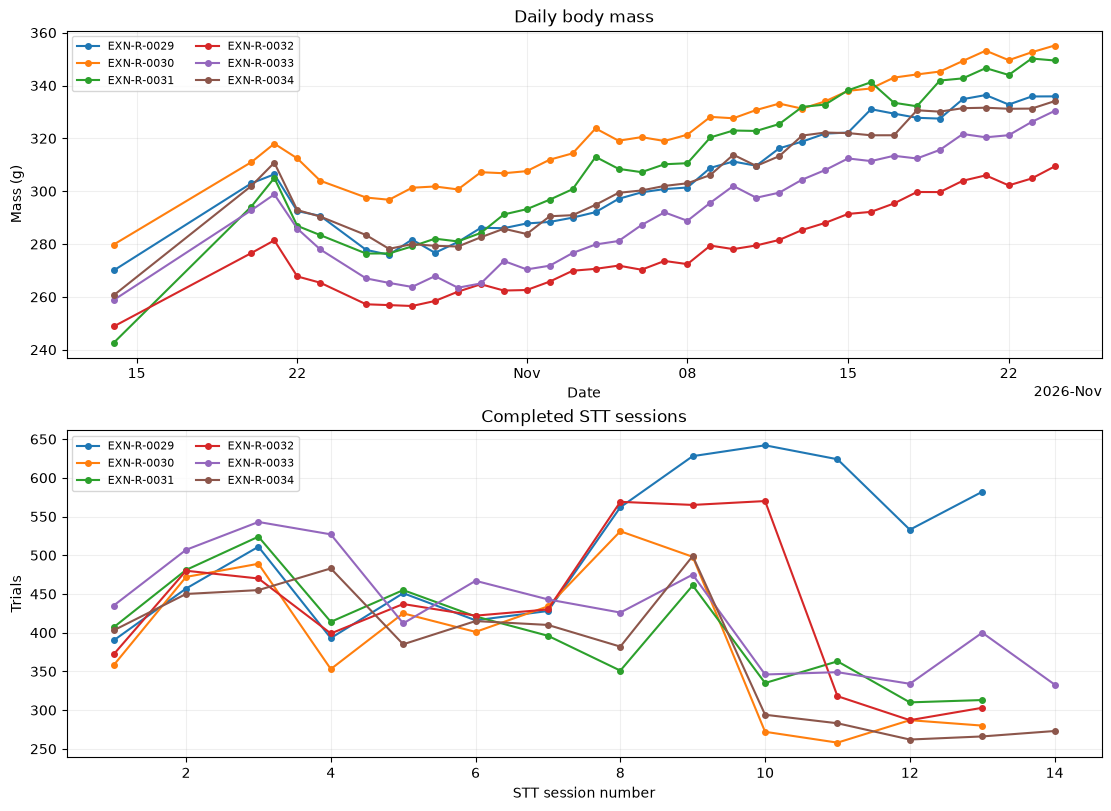

In [3]:
mass = cohort_query("""
    SELECT subjid AS rat, mdate AS date, mass
    FROM met.mass
    WHERE subjid IN :rats
    ORDER BY subjid, mdate
""")
mass["date"] = pd.to_datetime(mass["date"]).dt.normalize()
mass["mass"] = pd.to_numeric(mass["mass"], errors="coerce")
mass = mass.groupby(["rat", "date"], as_index=False)["mass"].mean()

training = sessions.loc[sessions["num_trials"].gt(0) & sessions["ended"].eq(1)].copy()
training["session_number"] = training.groupby("rat").cumcount() + 1
training["session_in_stage"] = training.groupby(["rat", "stage"]).cumcount() + 1

def plot_rats(ax, frame, x, y):
    for rat, rows in frame.groupby("rat", sort=False):
        ax.plot(rows[x], rows[y], color=COLORS[rat], marker="o", ms=4, label=rat)
    ax.grid(alpha=0.2)
    if ax.lines:
        ax.legend(ncol=2, fontsize=8)

fig, (ax_mass, ax_trials) = plt.subplots(2, 1, figsize=(11, 8), layout="constrained")
plot_rats(ax_mass, mass, "date", "mass")
ax_mass.set(title="Daily body mass", xlabel="Date", ylabel="Mass (g)")
locator = mdates.AutoDateLocator()
ax_mass.xaxis.set_major_locator(locator)
ax_mass.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

plot_rats(ax_trials, training, "session_number", "num_trials")
ax_trials.set(title="Completed STT sessions", xlabel="STT session number", ylabel="Trials")
ax_trials.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

## 3. 各阶段的 session performance

实线默认使用 rig 保存的值。表格中的重算值使用 `trialnum` 11–110，分子是 `hit=1 且 viol=0`，分母是窗口内全部有记录的 trial。少于 110 次时算到最后一个已记录的 trial，空窗口显示缺失。差值不为零的历史 session 需要核对当时的协议和 trial 记录。

**Session performance by stage**

By default, the lines show the values saved by the rig. The recalculated value uses trials numbered 11?110 and divides the number with `hit = 1` and `viol = 0` by all recorded trials in that window. For sessions with fewer than 110 trials, the window ends at the last recorded trial. An empty window is shown as missing. If the saved and recalculated values differ for a historical session, check the protocol version and trial records for that session.

,rat,date,session_id,stage,session_in_stage,trials_in_window,saved_pct,trials_11_110_pct,saved_minus_recomputed_pp,saved_a_streak
0,EXN-R-0029,2026-11-05,116883,stage_1,1,100,59.49,5.0,54.49,0
1,EXN-R-0029,2026-11-06,116944,stage_1,2,100,55.58,24.0,31.58,0
2,EXN-R-0029,2026-11-09,117025,stage_1,3,100,55.19,32.0,23.19,0
3,EXN-R-0029,2026-11-11,117160,stage_1,4,100,60.31,35.0,25.31,0
4,EXN-R-0029,2026-11-12,117238,stage_1,5,100,68.29,23.0,45.29,0
...,...,...,...,...,...,...,...,...,...,...
75,EXN-R-0034,2026-11-18,117609,stage_2,3,100,56.00,56.0,0.00,0
76,EXN-R-0034,2026-11-19,117678,stage_2,4,100,57.00,57.0,-0.00,0
77,EXN-R-0034,2026-11-20,117750,stage_2,5,100,61.00,61.0,0.00,1
78,EXN-R-0034,2026-11-23,117843,stage_2,6,100,63.00,63.0,0.00,2


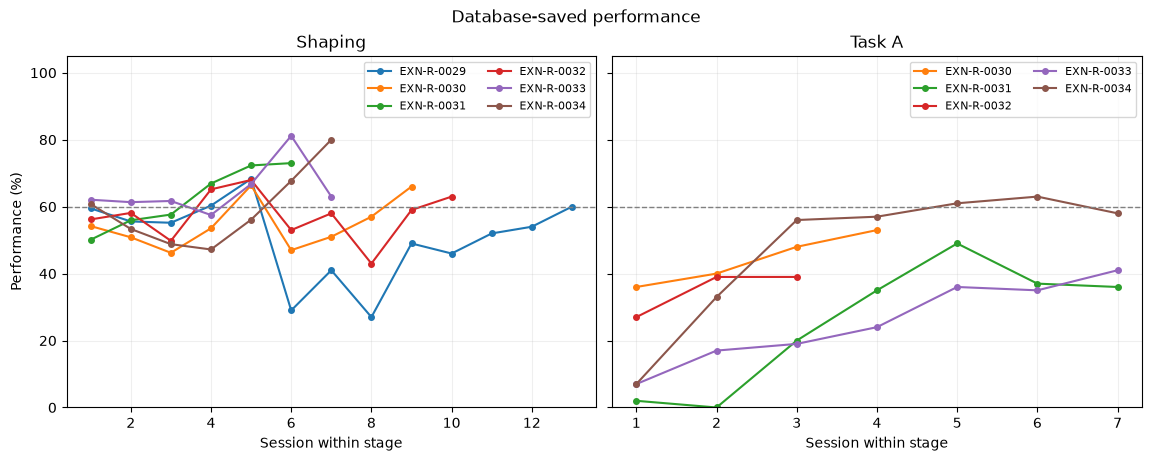

In [4]:
trial_sql = text("""
    SELECT t.sessid AS session_id, t.trialnum, t.hit, t.viol, t.RT AS rt
    FROM beh.trials AS t
    WHERE t.sessid IN :ids
    ORDER BY t.sessid, t.trialnum
""").bindparams(bindparam("ids", expanding=True))

session_ids = sorted(set(training["session_id"]) | set(today["session_id"]))
trial_columns = ["session_id", "trialnum", "hit", "viol", "rt"]
trials = (
    pd.read_sql_query(trial_sql, dbe, params={"ids": [int(s) for s in session_ids]})
    if session_ids else pd.DataFrame(columns=trial_columns)
)
for col in ["trialnum", "hit", "viol", "rt"]:
    trials[col] = pd.to_numeric(trials[col], errors="coerce")

trials["clean_success"] = (trials["hit"].eq(1) & trials["viol"].eq(0)).astype(float)
window = trials.loc[trials["trialnum"].between(11, 110)]
audit = window.groupby("session_id").agg(
    trials_in_window=("trialnum", "size"),
    clean_hits=("clean_success", "sum"),
)
audit["trials_11_110_pct"] = 100 * audit["clean_hits"] / audit["trials_in_window"]
performance = training.join(audit, on="session_id")
performance["saved_minus_recomputed_pp"] = performance["saved_pct"] - performance["trials_11_110_pct"]

display(performance[["rat", "date", "session_id", "stage", "session_in_stage",
                     "trials_in_window", "saved_pct", "trials_11_110_pct",
                     "saved_minus_recomputed_pp", "saved_a_streak"]].round({
    "saved_pct": 2, "trials_11_110_pct": 2, "saved_minus_recomputed_pp": 2,
}))

stages = [stage for stage in STAGES if stage != "stage_3" or performance["stage"].eq(stage).any()]
fig, axes = plt.subplots(1, len(stages), figsize=(5.7 * len(stages), 4.5),
                         sharey=True, squeeze=False, layout="constrained")
for ax, stage in zip(axes[0], stages):
    subset = performance.loc[performance["stage"].eq(stage)]
    plot_rats(ax, subset, "session_in_stage", PERFORMANCE_SOURCE)
    ax.axhline(ADVANCE_PCT, color="gray", ls="--", lw=1)
    ax.set(title=STAGES[stage], xlabel="Session within stage", ylim=(0, 105))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0, 0].set_ylabel("Performance (%)")
title = "Database-saved performance" if PERFORMANCE_SOURCE == "saved_pct" else "Performance in trials 11–110"
fig.suptitle(title)
plt.show()

## 4. 当天每个 session 内的 violation、performance 和 RT

Performance 用最近 20 个 trial 的无 violation 成功率。错误、失败和 timeout 仍计入窗口分母。RT 读取数据库记录，单位为秒，绘图仅使用正值。现行协议的 RT 从 MidC 到 reward、violation 或 timeout，因此用颜色标出是否成功取奖。

**Violations, performance, and RT within each session on the selected day**

Performance is the proportion of the last 20 trials that were successful and had zero violations. Trials with errors, unsuccessful trials, and timeouts still count in the denominator. RT is read from the database in seconds, and only positive values are plotted. The current protocol measures RT from the MidC poke until the trial ends in reward, violation, or timeout. The plot distinguishes trials that reached reward from other trials.

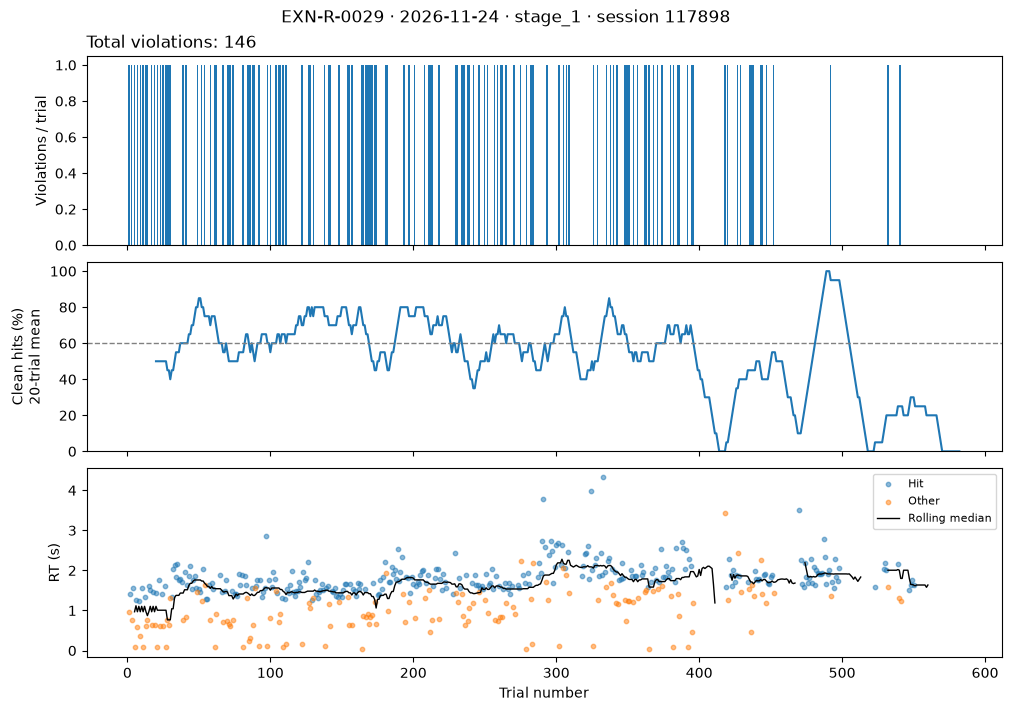

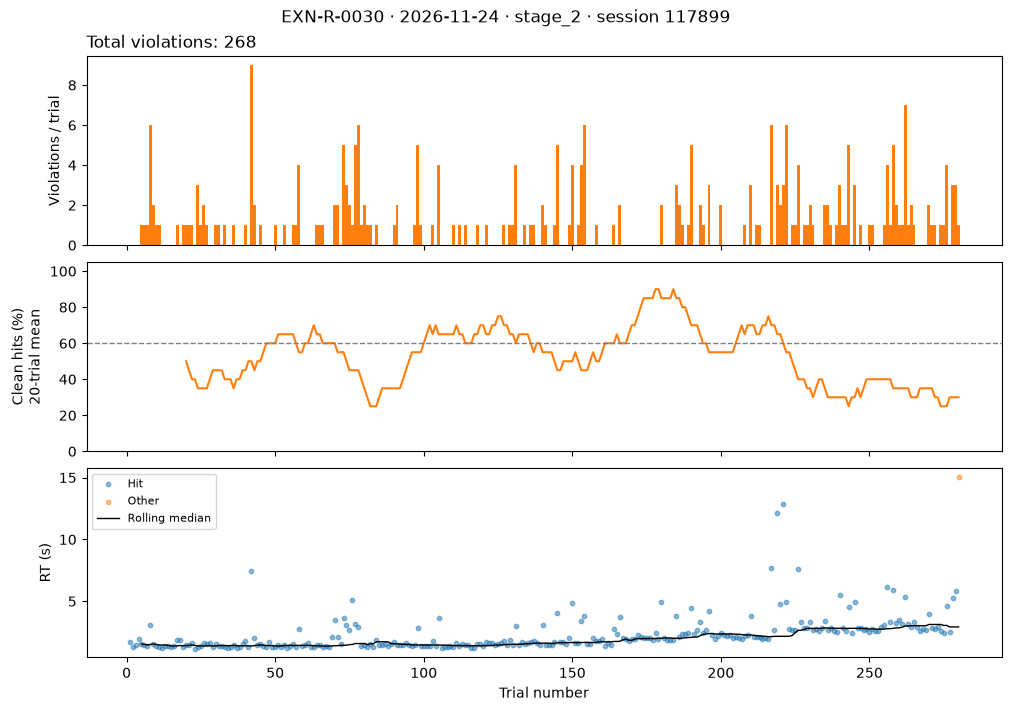

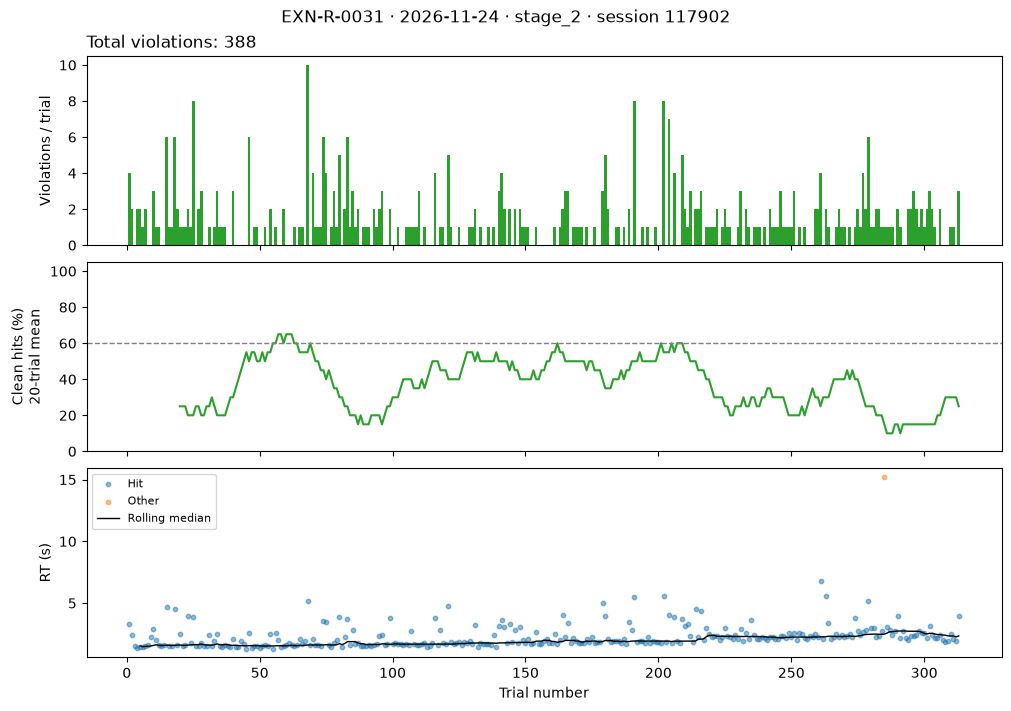

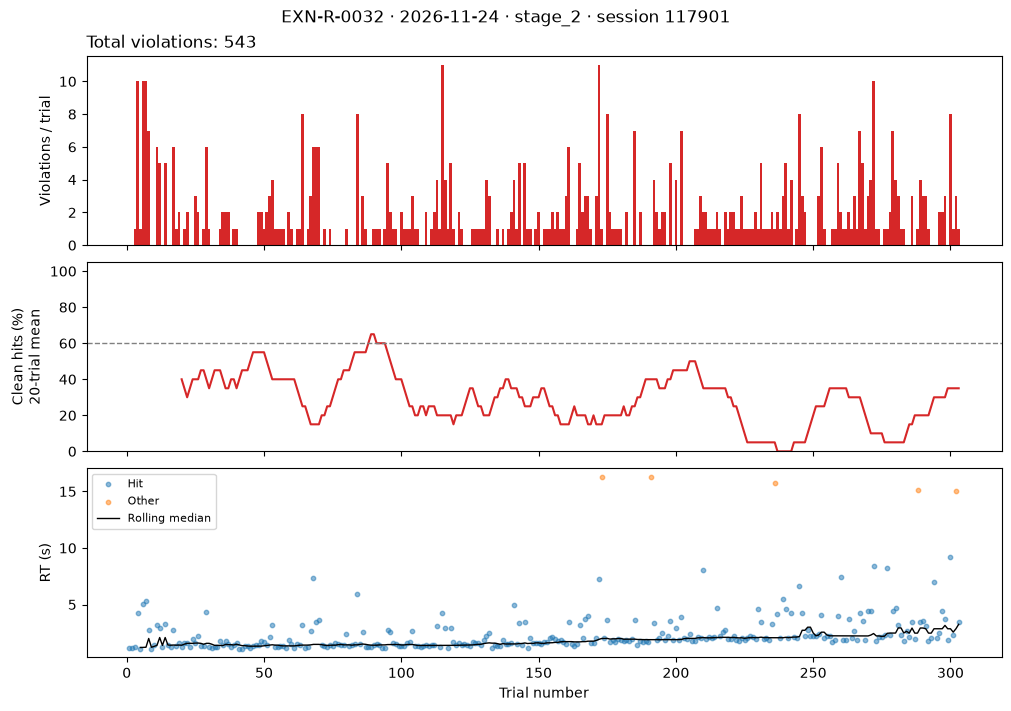

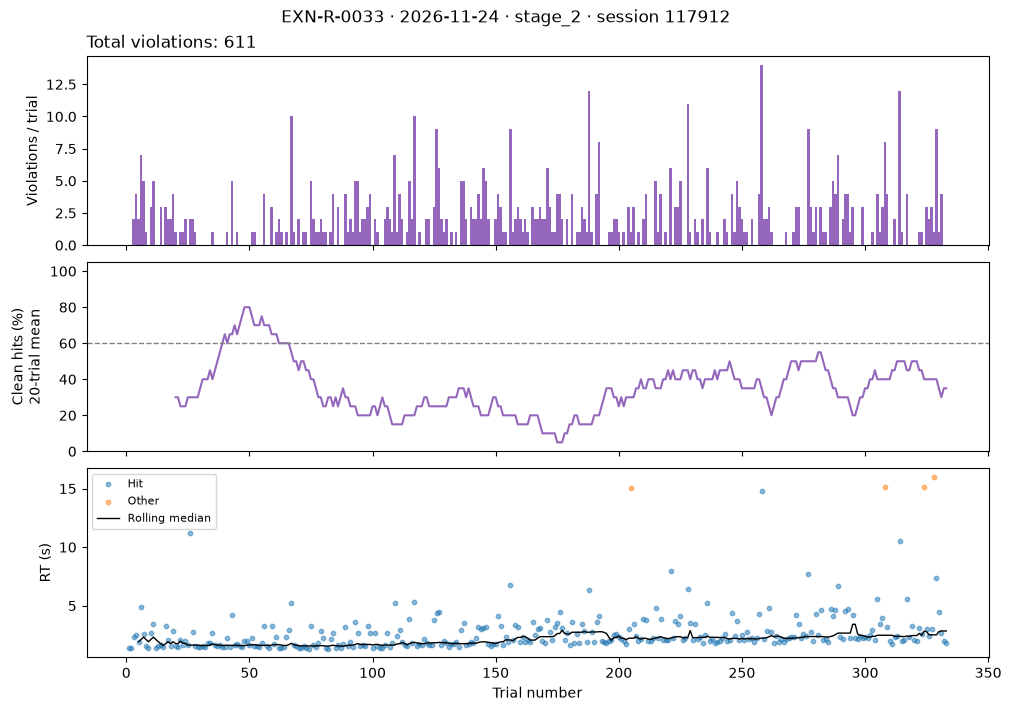

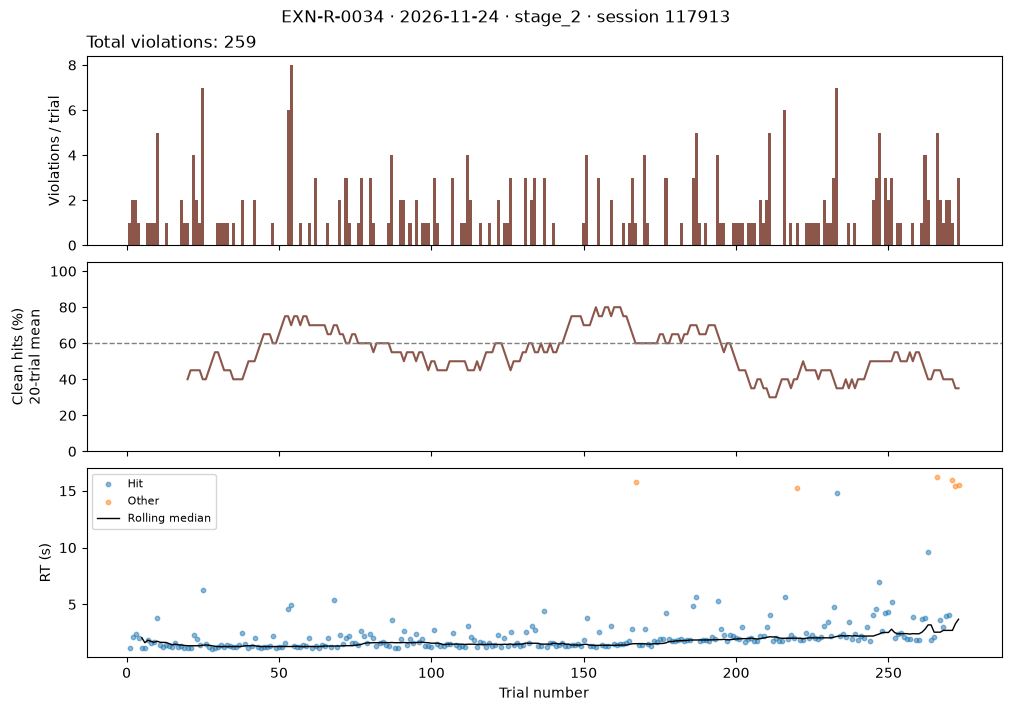

In [5]:
if today.empty:
    print(f"No STT sessions on {DAY.date()}.")
for row in today.itertuples(index=False):
    td = trials.loc[trials["session_id"].eq(row.session_id)].sort_values("trialnum")
    if td.empty:
        print(f"{row.rat} · {row.session_id}: no recorded trials")
        continue

    trial_number = td["trialnum"]
    rolling_perf = 100 * td["clean_success"].rolling(WINDOW, min_periods=WINDOW).mean()
    rt = td["rt"].where(td["rt"].gt(0))
    hit = td["hit"].eq(1)

    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout="constrained")
    axes[0].bar(trial_number, td["viol"], color=COLORS[row.rat], width=1)
    axes[0].set_ylabel("Violations / trial")
    total = td["viol"].sum(min_count=1)
    axes[0].set_title(f"Total violations: {total:g}", loc="left")

    axes[1].plot(trial_number, rolling_perf, color=COLORS[row.rat])
    axes[1].axhline(ADVANCE_PCT, color="gray", ls="--", lw=1)
    axes[1].set(ylabel=f"Clean hits (%)\n{WINDOW}-trial mean", ylim=(0, 105))

    axes[2].scatter(trial_number[hit], rt[hit], s=10, alpha=0.5, label="Hit")
    axes[2].scatter(trial_number[~hit], rt[~hit], s=10, alpha=0.5, label="Other")
    axes[2].plot(trial_number, rt.rolling(WINDOW, min_periods=5).median(),
                 color="black", lw=1, label="Rolling median")
    axes[2].set(xlabel="Trial number", ylabel="RT (s)")
    axes[2].legend(fontsize=8)
    fig.suptitle(f"{row.rat} · {DAY.date()} · {row.stage} · session {row.session_id}")
    plt.show()

## 5. Violation 发生在哪个 port

数据库的 `viol` 是总数。port 通过原始 poke-in 和状态时间重建，使用现行 STT 的计数窗口。只有当终止于 `Violation` 且此前未计到错误时，才尝试用状态切换时的 poke 补上协议记录的那一次。无法唯一定位的次数列为 `Unassigned`，并用核对表显示重建超过记录的次数。旧协议可能产生不同的计数结果。

第一张图显示当天每个 session 的各 port 次数。后面的热图显示每只鼠 across sessions 的变化。横轴在每个 stage 从 1 开始，颜色是每 100 个已记录 trial 的次数。

**Which ports were involved in violations?**

The database field `viol` records the total count. Port attribution is reconstructed from poke-in events and state timestamps using the counting windows in the current STT protocol. If the trial ended in `Violation` and no earlier error was counted, the code checks the poke at the transition into that state. Counts that cannot be assigned to a port are listed as `Unassigned`. The comparison table reports any excess inferred events. Older protocol versions may count violations differently.

The first plot shows the violation count by port for each session on the selected day. The heatmaps show how this distribution changes across sessions for each rat. Session numbering starts at 1 in each stage. Color represents violations per 100 trials with a saved violation count.

,rat,session_id,recorded_violations,trials_with_saved_viol,recorded_trials,missing_event_trials,excess_inferred_events,TopL,TopR,MidL,MidC,MidR,BotL,BotC,BotR,Unassigned
0,EXN-R-0029,117898,146,582,582,0,0,0,60,56,23,0,4,2,1,0
1,EXN-R-0030,117899,268,280,280,0,0,5,70,44,128,2,15,4,0,0
2,EXN-R-0031,117902,388,313,313,0,0,15,131,91,86,0,50,3,12,0
3,EXN-R-0032,117901,543,303,303,0,0,8,240,80,144,0,57,14,0,0
4,EXN-R-0033,117912,611,333,333,0,0,5,294,149,110,2,35,16,0,0
5,EXN-R-0034,117913,259,273,273,0,0,2,114,47,33,1,34,26,2,0


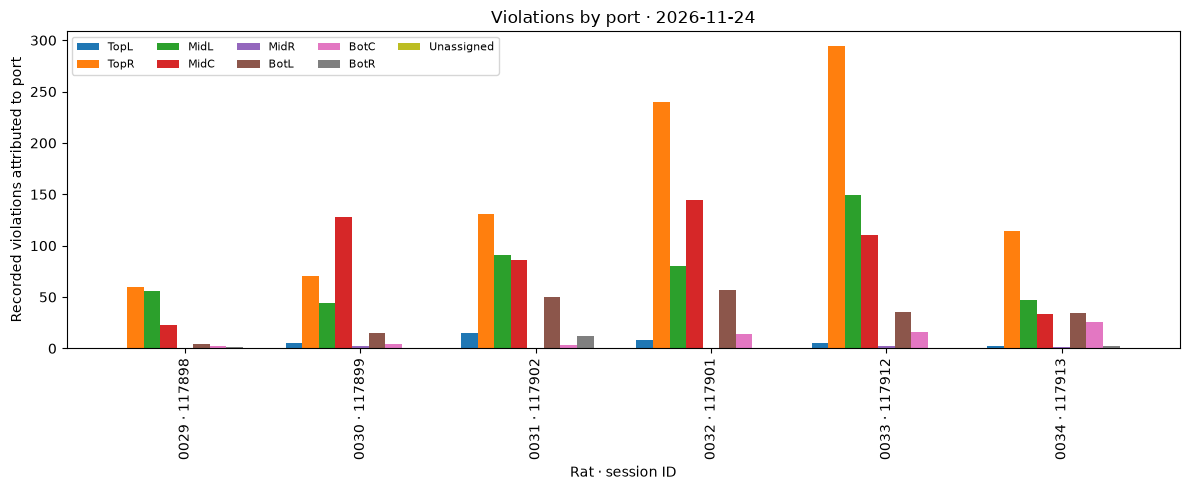

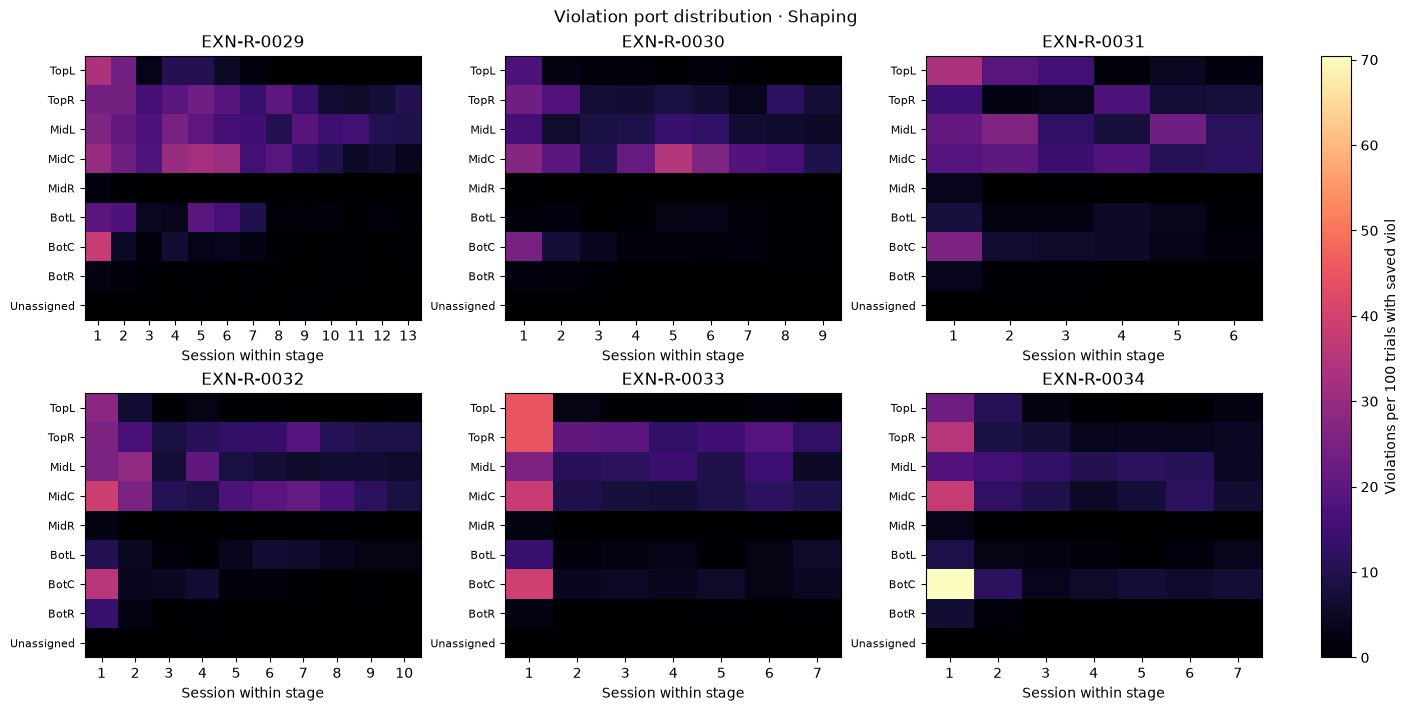

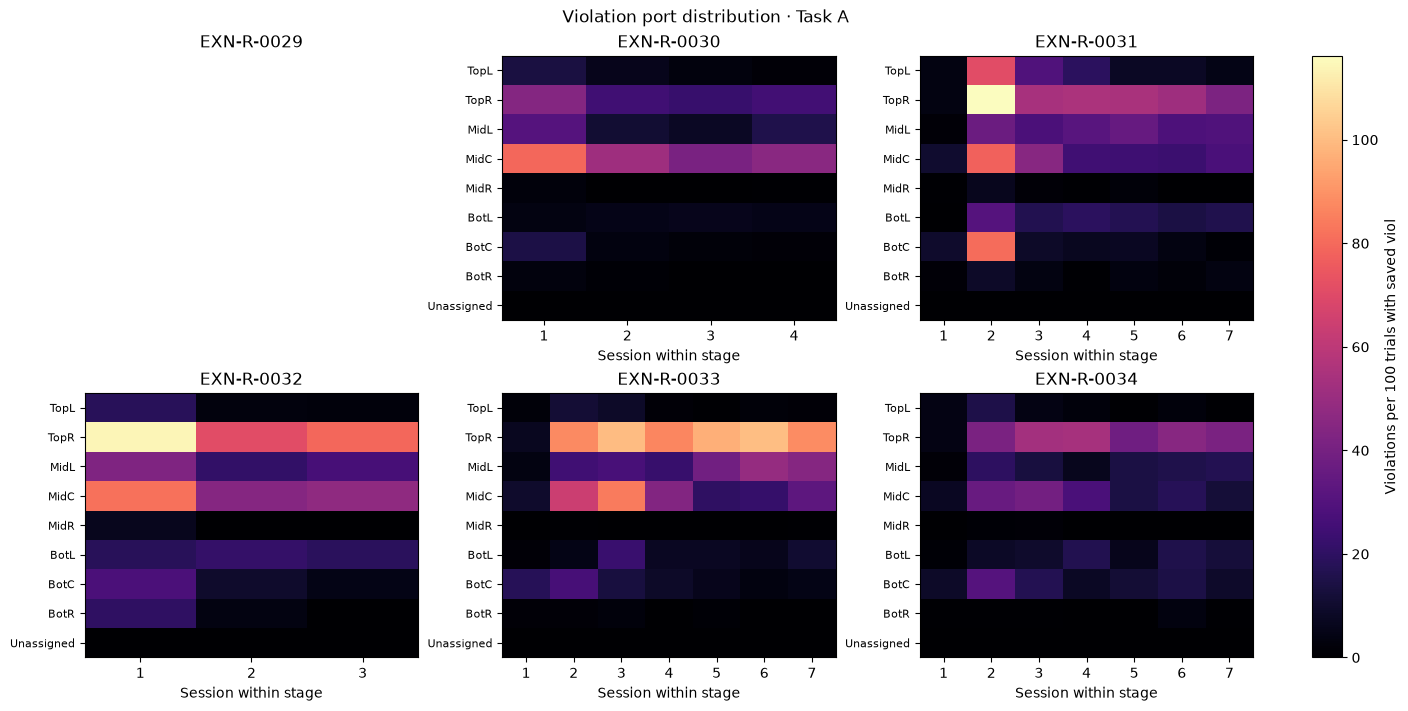

In [6]:
event_sql = text("""
    SELECT t.sessid AS session_id, t.trialnum, p.parsed_events
    FROM beh.trials AS t
    LEFT JOIN beh.parsed_events AS p ON p.trialid = t.trialid
    WHERE t.sessid = :session_id AND t.viol > 0
    ORDER BY t.trialnum
""")
EPS = 1e-4
PORT_BY_EVENT = {f"{port}In".lower(): port for port in PORTS}
CATEGORIES = PORTS + ["Unassigned"]

def first_entry(states, name):
    times = np.asarray(states.get(name), dtype=float)
    if times.ndim == 2 and times.shape[1] == 2:
        entries = times[:, 0]
    else:
        flat = times.ravel()
        entries = flat[:max(1, flat.size // 2)]  # fmt 2 stores arrays column first
    finite = entries[np.isfinite(entries)]
    return finite[0] if finite.size else np.nan

def infer_violation_events(parsed):
    states = parsed.get("States") or {}
    events = parsed.get("Events") or {}
    correct = [first_entry(states, f"Correct{k}") for k in range(1, 5)]
    finish_violation = first_entry(states, "Violation")
    finish = next(
        (t for t in [first_entry(states, "RewardDelivery"), finish_violation,
                     first_entry(states, "TrialTimeOut")] if np.isfinite(t)),
        np.nan,
    )
    if not np.isfinite(correct[0]) or not np.isfinite(finish):
        return []

    pokes = []
    for name, values in events.items():
        port = PORT_BY_EVENT.get(name.lower())
        if port is not None:
            times = np.asarray(values, dtype=float).ravel()
            pokes.extend((t, port) for t in times if np.isfinite(t))

    found = []
    for step, start in enumerate(correct):
        if not np.isfinite(start):
            break
        next_correct = correct[step + 1] if step < 3 else np.nan
        stop = next_correct if np.isfinite(next_correct) else finish
        found.extend((port, t, step + 1) for t, port in pokes if start + EPS < t < stop - EPS)

    if not found and np.isfinite(finish_violation) and finish == finish_violation:
        terminal_ports = {port for t, port in pokes if abs(t - finish) <= EPS}
        if len(terminal_ports) == 1:
            last_step = sum(np.isfinite(t) and t <= finish for t in correct)
            port = terminal_ports.pop()
            time = min((t for t, p in pokes if p == port and abs(t - finish) <= EPS),
                       key=lambda t: abs(t - finish))
            found.append((port, time, last_step))
    return found

port_rows = []
for session_id, td in trials.groupby("session_id", sort=False):
    wrong = td.loc[td["viol"].gt(0)]
    counts_by_port = dict.fromkeys(CATEGORIES, 0)
    excess = 0
    missing_events = 0
    if not wrong.empty:
        raw_events = pd.read_sql_query(event_sql, dbe, params={"session_id": int(session_id)})
        by_trial = raw_events.set_index("trialnum")["parsed_events"]
        for trial in wrong.itertuples(index=False):
            parsed = payload(by_trial.get(trial.trialnum))
            missing_events += int(not parsed)
            inferred = infer_violation_events(parsed)
            recorded = int(trial.viol)
            if len(inferred) > recorded:
                # The timestamps do not explain which events were recorded.
                excess += len(inferred) - recorded
                inferred = []
            for port, _, _ in inferred:
                counts_by_port[port] += 1
            counts_by_port["Unassigned"] += recorded - len(inferred)

    port_rows.append({
        "session_id": session_id, "recorded_trials": len(td),
        "recorded_violations": td["viol"].sum(min_count=1),
        "trials_with_saved_viol": td["viol"].count(),
        "excess_inferred_events": excess, "missing_event_trials": missing_events,
        **counts_by_port,
    })

port_columns = [
    "session_id", "recorded_trials", "recorded_violations", "trials_with_saved_viol",
    "excess_inferred_events", "missing_event_trials", *CATEGORIES,
]
port_counts = pd.DataFrame(port_rows, columns=port_columns)
today_ports = today.merge(port_counts, on="session_id", how="inner")
audit_cols = [
    "rat", "session_id", "recorded_violations", "trials_with_saved_viol", "recorded_trials",
    "missing_event_trials", "excess_inferred_events", *CATEGORIES,
]
display(today_ports[audit_cols])

if not today_ports.empty:
    labels = today_ports["rat"].str[-4:] + " · " + today_ports["session_id"].astype(str)
    ax = today_ports.set_index(labels)[CATEGORIES].plot.bar(figsize=(12, 5), width=0.85)
    ax.set(title=f"Violations by port · {DAY.date()}", xlabel="Rat · session ID",
           ylabel="Recorded violations attributed to port")
    ax.legend(ncol=5, fontsize=8)
    plt.tight_layout()
    plt.show()

history_ports = training.merge(port_counts, on="session_id", how="inner")
history_ports = history_ports.loc[history_ports["trials_with_saved_viol"].gt(0)]
for stage, frame in history_ports.groupby("stage", sort=False):
    rates = frame[CATEGORIES].div(frame["trials_with_saved_viol"], axis=0) * 100
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout="constrained")
    for rat, ax in zip(RATS, axes.flat):
        rows = frame.loc[frame["rat"].eq(rat)]
        ax.set_title(rat)
        if rows.empty:
            ax.set_axis_off()
            continue
        image = ax.imshow(rates.loc[rows.index].T, aspect="auto", cmap="magma",
                          vmin=0, vmax=max(1.0, rates.to_numpy().max()))
        ax.set_xticks(range(len(rows)), rows["session_in_stage"].astype(int))
        ax.set_yticks(range(len(CATEGORIES)), CATEGORIES, fontsize=8)
        ax.set_xlabel("Session within stage")
    fig.colorbar(image, ax=axes, label="Violations per 100 trials with saved viol")
    fig.suptitle(f"Violation port distribution · {STAGES.get(stage, stage)}")
    plt.show()

## 6. 单个 session 中，指定 port 的 violation 发生在哪一步

从第 1 节复制 `session_id`，修改下方 `SESSION_ID` 和 `VIOLATION_PORT` 后重新运行这一格。默认查看 34 号上次核对的 session 和 TopR。结果按**上一次正确 poke**和**下一目标**汇总，并列出每次事件的 trial 编号及时间。第 4 步之后的下一目标是奖赏口 BotC。数据来自已保存的 poke 和状态事件。无法定位的记录单独报告。

热图显示同一 session 的所有 port。每个格子的数字是该 port 在该步骤的 violation 次数。

**Where in the sequence did a violation occur?**

Set `SESSION_ID` and `VIOLATION_PORT` below and rerun this cell. The heatmap shows all ports in the session, with the violation count in each cell. The summary groups events by the last accepted poke and the next target. The detail table shows each matching event, its trial number, and its time from trial start. BotC is the reward target after step 4. Events that cannot be assigned are reported separately.

Session 117898 · TopR: 60 attributed events
Unassigned recorded violations across all ports: 0


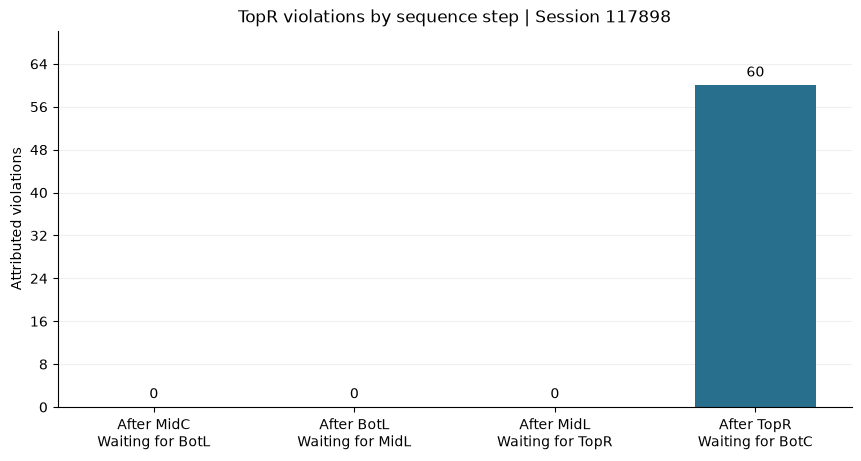

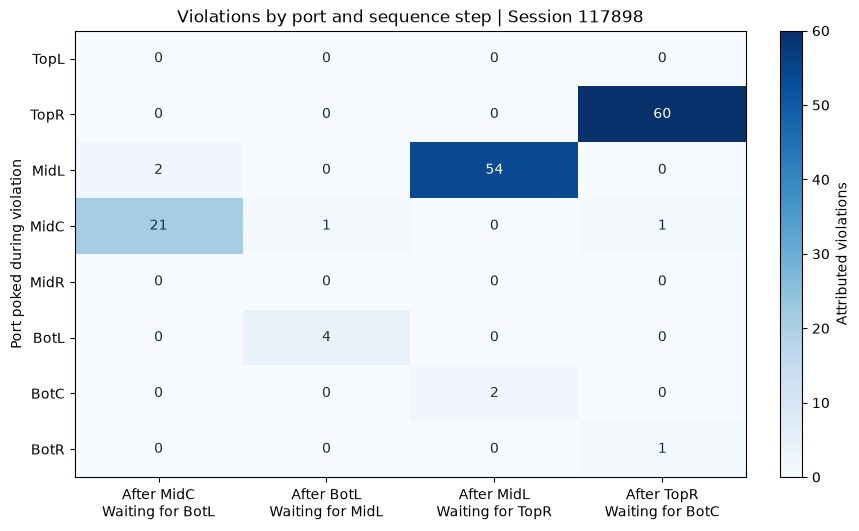

,after_step,last_correct_port,next_target,violations
0,4,TopR,BotC,60


,trialnum,violation_port,after_step,last_correct_port,next_target,time_in_trial_s
0,1,TopR,4,TopR,BotC,12.2299
16,30,TopR,4,TopR,BotC,1.3433
19,49,TopR,4,TopR,BotC,1.4659
20,52,TopR,4,TopR,BotC,1.2726
21,54,TopR,4,TopR,BotC,1.8806
31,84,TopR,4,TopR,BotC,1.4011
39,104,TopR,4,TopR,BotC,1.8101
45,127,TopR,4,TopR,BotC,1.2393
46,128,TopR,4,TopR,BotC,1.2940
47,130,TopR,4,TopR,BotC,2.3040


In [13]:
SESSION_ID = 117898
VIOLATION_PORT = "TopR"  # e.g. "MidL", "BotC"

if VIOLATION_PORT not in PORTS:
    raise ValueError(f"Choose a port from {', '.join(PORTS)}.")

position_sql = text("""
    SELECT t.trialnum, t.viol, p.parsed_events, d.data AS trial_data
    FROM beh.trials AS t
    LEFT JOIN beh.parsed_events AS p ON p.trialid = t.trialid
    LEFT JOIN beh.trial_data AS d ON d.trialid = t.trialid
    WHERE t.sessid = :session_id AND t.viol > 0
    ORDER BY t.trialnum
""")
wrong_trials = pd.read_sql_query(position_sql, dbe, params={"session_id": SESSION_ID})
rows = []
sequences = set()
unassigned = 0
for trial in wrong_trials.itertuples(index=False):
    events = infer_violation_events(payload(trial.parsed_events))
    recorded = int(trial.viol)
    if len(events) > recorded:
        events = []
    unassigned += recorded - len(events)

    sequence = payload(trial.trial_data).get("target_sequence")
    targets = [*sequence, "BotC"] if isinstance(sequence, list) and len(sequence) == 4 else None
    if targets:
        sequences.add(tuple(targets))
    for port, timestamp, step in events:
        rows.append({
            "trialnum": trial.trialnum,
            "violation_port": port,
            "after_step": step,
            "last_correct_port": targets[step - 1] if targets and 1 <= step <= 4 else "Unknown",
            "next_target": targets[step] if targets and 1 <= step <= 4 else "Unknown",
            "time_in_trial_s": timestamp,
        })

all_details = pd.DataFrame(rows, columns=[
    "trialnum", "violation_port", "after_step", "last_correct_port",
    "next_target", "time_in_trial_s",
]).sort_values(["trialnum", "time_in_trial_s"])
selected = all_details.loc[all_details["violation_port"].eq(VIOLATION_PORT)]
print(f"Session {SESSION_ID} · {VIOLATION_PORT}: {len(selected)} attributed events")
print(f"Unassigned recorded violations across all ports: {unassigned}")
if not wrong_trials.empty:
    steps = list(range(1, 5))
    counts_by_step = selected["after_step"].value_counts().reindex(steps, fill_value=0).tolist()
    labels = [f"After step {step}" for step in steps]
    if len(sequences) == 1:
        targets = next(iter(sequences))
        labels = [f"After {targets[k - 1]}\nWaiting for {targets[k]}" for k in steps]
    fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
    bars = ax.bar(steps, counts_by_step, width=0.6, color="#286f8d")
    ax.bar_label(bars, padding=4)
    ax.set_xticks(steps, labels)
    ax.set(title=f"{VIOLATION_PORT} violations by sequence step | Session {SESSION_ID}",
           ylabel="Attributed violations", ylim=(0, max(counts_by_step + [4]) * 1.17))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    plt.show()

    port_by_step = (all_details.groupby(["violation_port", "after_step"]).size()
                    .unstack(fill_value=0).reindex(index=PORTS, columns=steps, fill_value=0))
    fig_ports, ax_ports = plt.subplots(figsize=(8.5, 5.2), layout="constrained")
    vmax = max(1, port_by_step.to_numpy().max())
    heatmap = ax_ports.imshow(port_by_step, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for i, values in enumerate(port_by_step.to_numpy()):
        for j, count in enumerate(values):
            ax_ports.text(j, i, str(count), ha="center", va="center",
                          color="white" if count > 0.55 * vmax else "#162f45")
    ax_ports.set_xticks(range(len(steps)), labels)
    ax_ports.set_yticks(range(len(PORTS)), PORTS)
    ax_ports.set(title=f"Violations by port and sequence step | Session {SESSION_ID}",
                 ylabel="Port poked during violation")
    fig_ports.colorbar(heatmap, ax=ax_ports, label="Attributed violations")
    plt.show()
if not selected.empty:
    details = selected
    groups = ["after_step", "last_correct_port", "next_target"]
    by_step = details.groupby(groups).size().rename("violations").reset_index()
    display(by_step)
    display(details.round({"time_in_trial_s": 4}))
elif wrong_trials.empty:
    print("No trials with recorded violations were found for this session ID.")
else:
    print("No recorded violation could be attributed to the selected port.")

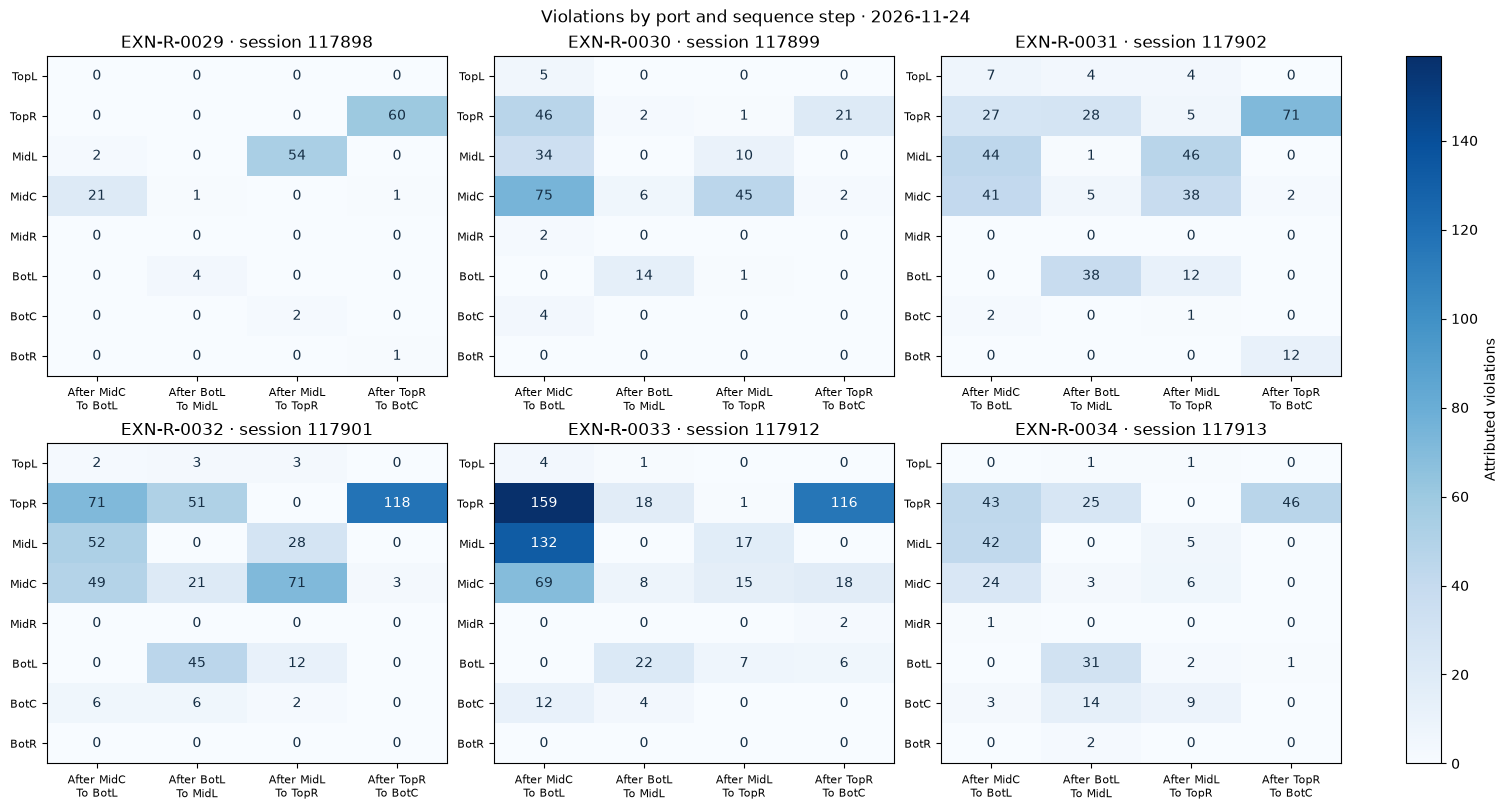

In [14]:
# 依赖前面已运行的第 6 节
picked = (
    today.sort_values("session_id")
    .drop_duplicates("rat", keep="last")
    .set_index("rat")
)

steps = [1, 2, 3, 4]
panels = {}

for rat in RATS:
    if rat not in picked.index:
        continue

    sid = int(picked.loc[rat, "session_id"])
    wrong = pd.read_sql_query(position_sql, dbe, params={"session_id": sid})
    counts = pd.DataFrame(0, index=PORTS, columns=steps)
    sequences = set()

    for trial in wrong.itertuples(index=False):
        sequence = payload(trial.trial_data).get("target_sequence")
        if isinstance(sequence, list) and len(sequence) == 4:
            sequences.add(tuple(sequence) + ("BotC",))

        events = infer_violation_events(payload(trial.parsed_events))
        if len(events) <= int(trial.viol):
            for port, _, step in events:
                if step in steps:
                    counts.loc[port, step] += 1

    labels = [f"After step {step}" for step in steps]
    if len(sequences) == 1:
        targets = next(iter(sequences))
        labels = [f"After {targets[k-1]}\nTo {targets[k]}" for k in steps]

    panels[rat] = (sid, counts, labels)

if not panels:
    print(f"{DAY.date()} 没有 STT session")
else:
    # 所有小图共享颜色刻度，方便比较同样深浅代表的次数。
    vmax = max(1, max(counts.to_numpy().max()
                      for _, counts, _ in panels.values()))

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for rat, ax in zip(RATS, axes.flat):
        if rat not in panels:
            ax.set_title(f"{rat} · no session")
            ax.set_axis_off()
            continue

        sid, counts, labels = panels[rat]
        image = ax.imshow(counts, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
        for i, row in enumerate(counts.to_numpy()):
            for j, count in enumerate(row):
                ax.text(j, i, str(count), ha="center", va="center",
                        color="white" if count > 0.55 * vmax else "#162f45")

        ax.set_title(f"{rat} · session {sid}")
        ax.set_xticks(range(4), labels, fontsize=8)
        ax.set_yticks(range(len(PORTS)), PORTS, fontsize=8)

    fig.colorbar(image, ax=axes, label="Attributed violations")
    fig.suptitle(f"Violations by port and sequence step · {DAY.date()}")
    plt.show()